alyssa zahra maharani asriandy

2300015003

In [ ]:
%pip install wget

from pathlib import Path
import os

os.environ["KERAS_HOME"] = str(Path.cwd() / ".tools" / "keras")

import zipfile
import wget
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow:", tf.__version__)
print("GPU:", gpus if gpus else "Tidak terdeteksi; pelatihan menggunakan CPU.")

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9686 sha256=d38cc77b4397c330dafa4f94b5ddfe73d3d842af985101b4daf166b0a58d746e
  Stored in directory: /root/.cache/pip/wheels/8a/b8/04/0c88fb22489b0c049bee4e977c5689c7fe597d6c4b0e7d0b6a
Successfully built wget
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")

    arsip.extractall(data_dir)

image_dir = data_dir / "dataset" / "Images"

print("Folder gambar:", image_dir)

Folder gambar: data/dataset/Images


In [ ]:
nama_kelas = sorted(
    folder.name for folder in image_dir.iterdir()
    if folder.is_dir()
)

gambar, label = [], []

for kelas, nama in enumerate(nama_kelas):
    for path in sorted((image_dir / nama).glob("*.tif")):
        with Image.open(path) as img:
            img = img.convert("RGB").resize(
                IMG_SIZE,
                Image.Resampling.BILINEAR)
            gambar.append(np.asarray(img))
        label.append(kelas)

X = np.asarray(gambar, dtype="uint8")
y = np.asarray(label, dtype="int32")

del gambar

assert len(nama_kelas) == 21 and len(X) == 2100, \
    "Periksa kelengkapan dataset"

assert np.all(np.bincount(y) == 100), \
    "Setiap kelas seharusnya memiliki 100 gambar"

print("Bentuk data:", X.shape)
print("Kelas:", nama_kelas)

Bentuk data: (2100, 224, 224, 3)
Kelas: ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


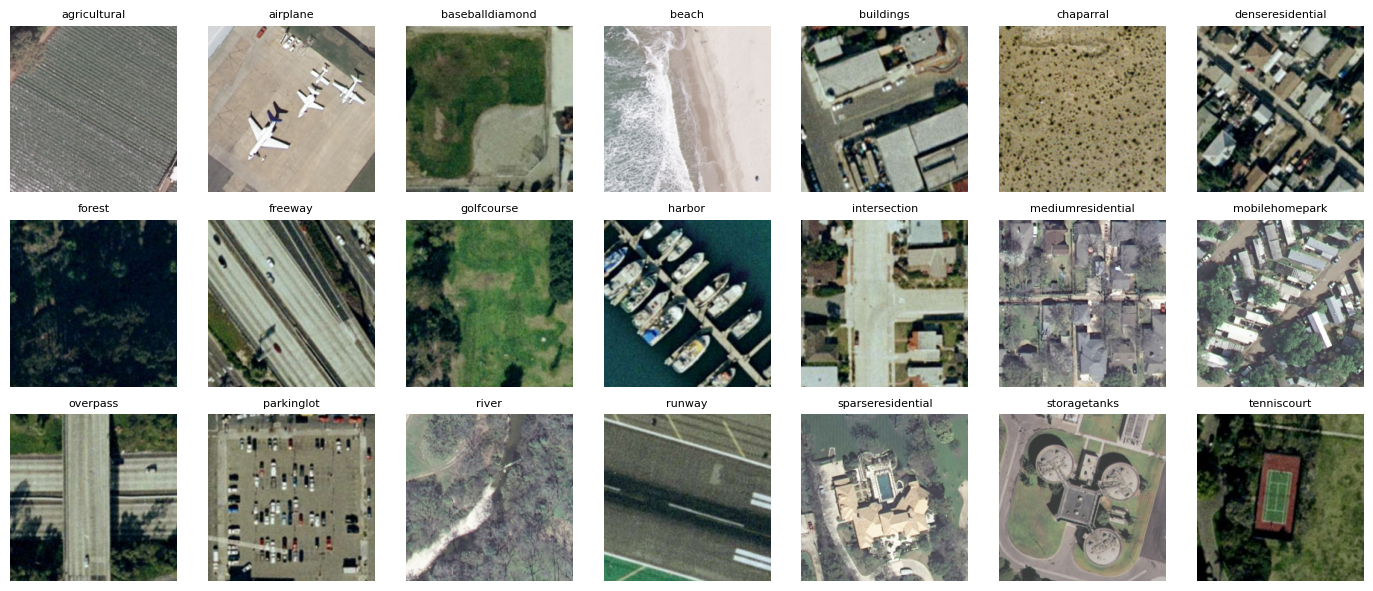

In [ ]:
fig, axes = plt.subplots(3, 7, figsize=(14, 6))

for kelas, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y == kelas)[0]
    ax.imshow(X[idx])
    ax.set_title(nama_kelas[kelas], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
x_train, x_sisa, y_train, y_sisa = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

x_val, x_test, y_val, y_test = train_test_split(
    x_sisa,
    y_sisa,
    test_size=0.50,
    stratify=y_sisa,
    random_state=42
)

print(
    "Train:",
    len(y_train),
    "Validation:",
    len(y_val),
    "Test:",
    len(y_test)
)

Train: 1470 Validation: 315 Test: 315


In [ ]:
# Arsitektur VGG16 (pretrained ImageNet) sebagai ekstraktor fitur.
# Untuk VGG19, ganti VGG16 -> VGG19 dan vgg16 -> vgg19.
base_model = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

# VGG memakai preprocessing sendiri (RGB -> BGR, kurangi mean ImageNet)
x = tf.keras.applications.vgg16.preprocess_input(inputs)
x = base_model(x, training=False)

# Classifier bergaya VGG: Flatten + Fully Connected + Dropout
x = tf.keras.layers.Flatten()(x)
x = tf.keras.layers.Dense(256, activation="relu")(x)
x = tf.keras.layers.Dropout(0.5)(x)

outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="vgg16_ucmerced"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print("Backbone dibekukan:", not base_model.trainable)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 25088)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  6,422,784 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 21)        │      5,397 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,142,869 (80.65 MB)

 Trainable params: 6,428,181 (24.52 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Backbone dibekukan: True


In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan:", len(history.history["loss"]))

Epoch 1/10
92/92 - 20s - 221ms/step - accuracy: 0.4000 - loss: 5.7651 - val_accuracy: 0.7587 - val_loss: 0.9459
Epoch 2/10
92/92 - 7s - 78ms/step - accuracy: 0.8068 - loss: 0.8079 - val_accuracy: 0.8159 - val_loss: 0.6900
Epoch 3/10
92/92 - 7s - 79ms/step - accuracy: 0.8857 - loss: 0.4107 - val_accuracy: 0.8476 - val_loss: 0.5759
Epoch 4/10
92/92 - 7s - 80ms/step - accuracy: 0.9218 - loss: 0.2700 - val_accuracy: 0.8635 - val_loss: 0.6164
Epoch 5/10
92/92 - 8s - 83ms/step - accuracy: 0.9503 - loss: 0.1710 - val_accuracy: 0.8762 - val_loss: 0.5175
Epoch 6/10
92/92 - 8s - 85ms/step - accuracy: 0.9680 - loss: 0.1112 - val_accuracy: 0.8857 - val_loss: 0.5393
Epoch 7/10
92/92 - 8s - 87ms/step - accuracy: 0.9660 - loss: 0.1097 - val_accuracy: 0.8762 - val_loss: 0.5059
Epoch 8/10
92/92 - 8s - 90ms/step - accuracy: 0.9776 - loss: 0.0799 - val_accuracy: 0.8952 - val_loss: 0.4610
Epoch 9/10
92/92 - 9s - 93ms/step - accuracy: 0.9762 - loss: 0.1090 - val_accuracy: 0.9175 - val_loss: 0.4171
Epoch 10

Test loss: 0.5870 | Test accuracy: 89.52%
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        15
         airplane       1.00      0.87      0.93        15
  baseballdiamond       0.88      1.00      0.94        15
            beach       1.00      1.00      1.00        15
        buildings       0.83      0.67      0.74        15
        chaparral       1.00      0.93      0.97        15
 denseresidential       0.81      0.87      0.84        15
           forest       0.88      1.00      0.94        15
          freeway       1.00      0.93      0.97        15
       golfcourse       0.93      0.93      0.93        15
           harbor       1.00      1.00      1.00        15
     intersection       0.79      1.00      0.88        15
mediumresidential       0.58      0.73      0.65        15
   mobilehomepark       0.86      0.80      0.83        15
         overpass       0.92      0.80      0.86        15
       parkin

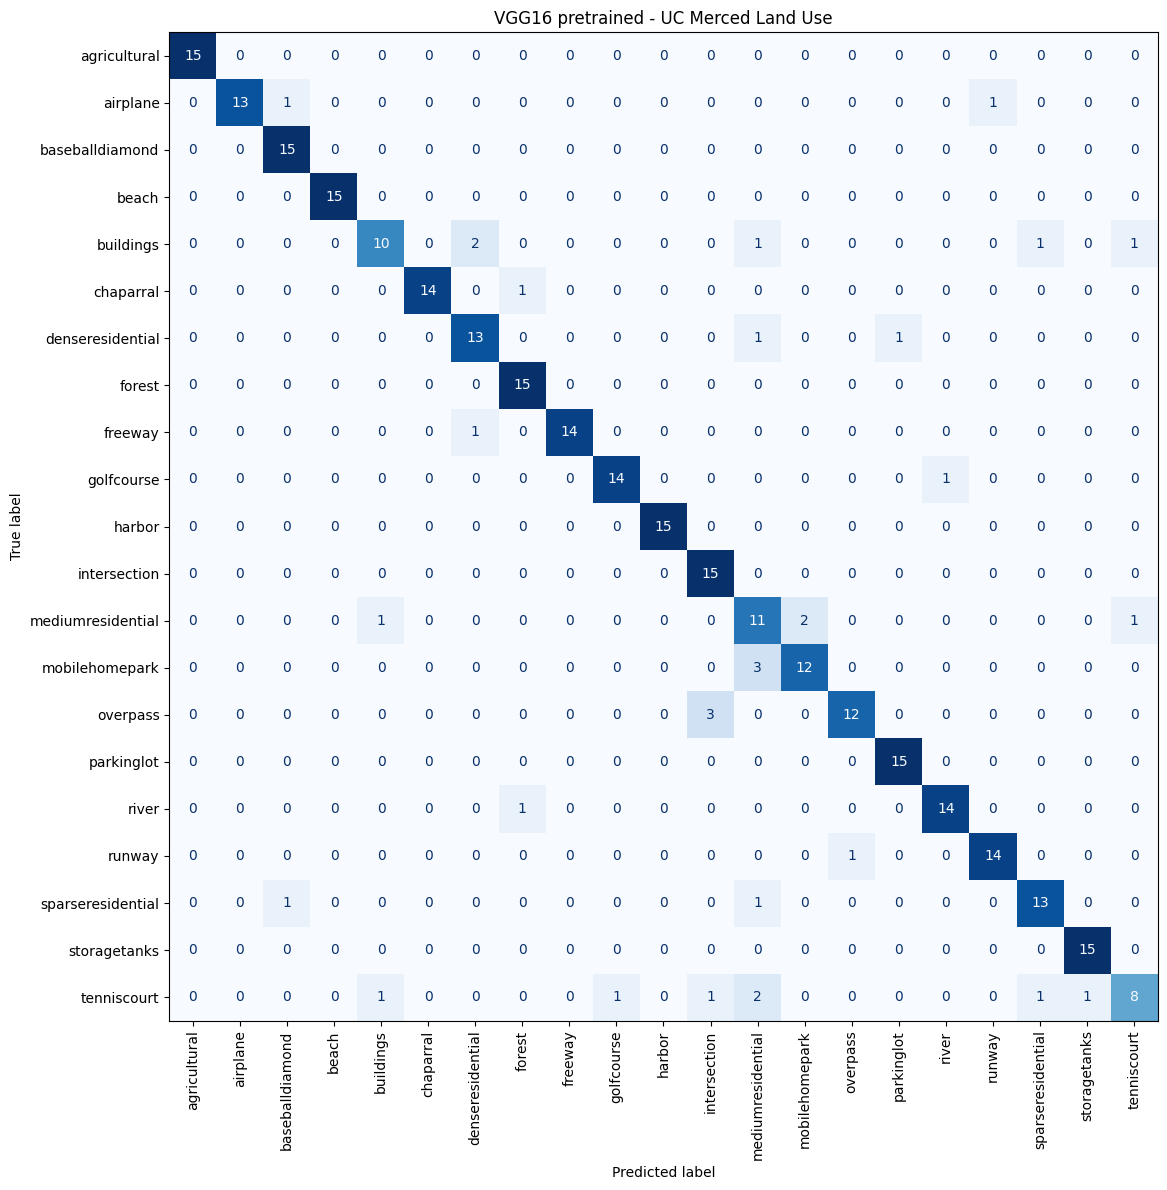

In [ ]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss: {test_loss:.4f} | "
    f"Test accuracy: {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("VGG16 pretrained - UC Merced Land Use")

plt.tight_layout()
plt.show()

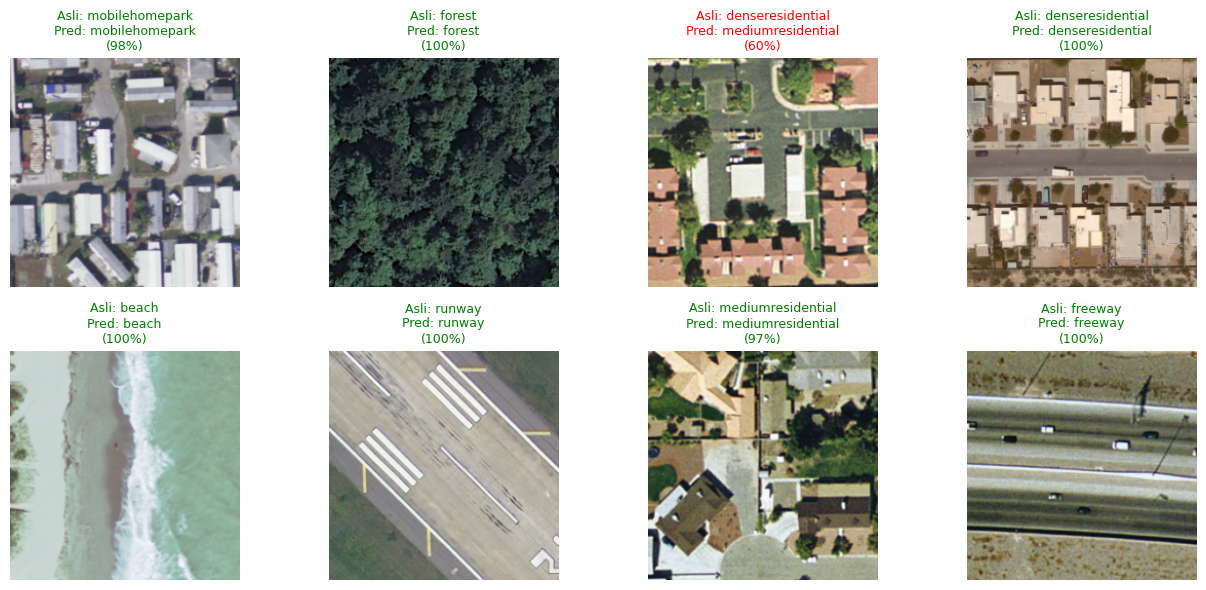

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]}\n"
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()